In [27]:
# %pip install yfinance

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

In [29]:
# Load Real Stock Data
# Reliance Industries Limited (RELIANCE.NS)

df  = yf.download("RELIANCE.NS",start="2025-01-01",end="2026-01-01")
df.head()

# Save The Data

# df.to_csv("Reliance.csv")


[*********************100%***********************]  1 of 1 completed

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2025-01-01,1210.793579,1215.800389,1201.226179,1204.448352,5892590
2025-01-02,1231.167725,1233.794938,1209.554328,1210.793626,15486276
2025-01-03,1240.437622,1251.244320,1224.921594,1233.249697,15521102
2025-01-06,1207.571533,1251.194807,1204.597219,1243.213682,14816766
2025-01-07,1230.225708,1233.844481,1210.793549,1211.537128,10070505


In [30]:
df.columns

MultiIndex([( 'Close', 'RELIANCE.NS'),
            (  'High', 'RELIANCE.NS'),
            (   'Low', 'RELIANCE.NS'),
            (  'Open', 'RELIANCE.NS'),
            ('Volume', 'RELIANCE.NS')],
           names=['Price', 'Ticker'])

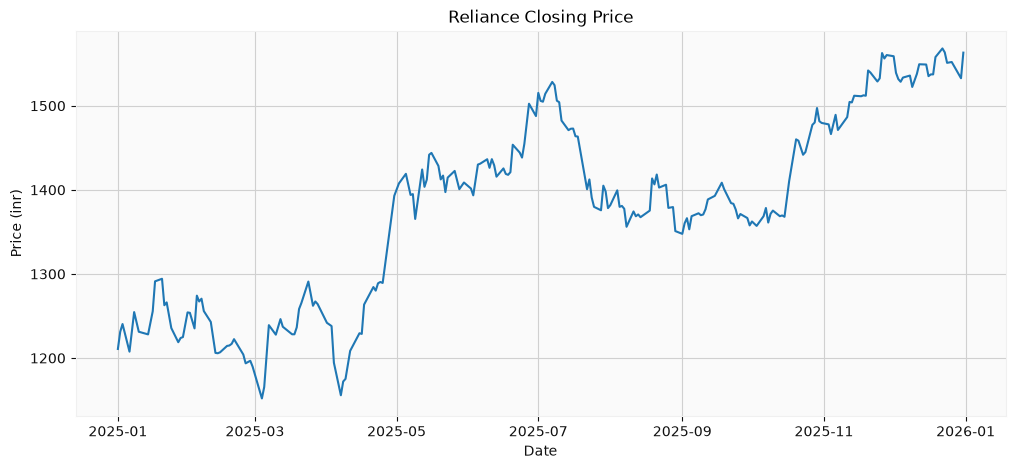

In [31]:
# Claosing Price Trend
plt.figure(figsize=(12,5))
plt.plot(df["Close"])
plt.title("Reliance Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (inr)")
plt.grid(True)
plt.show()

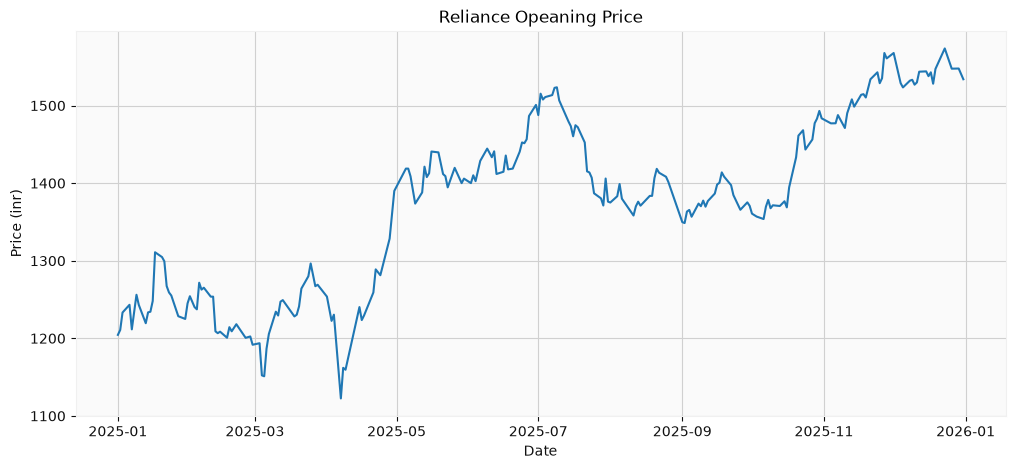

In [32]:
# Opeaning Price Trend

plt.figure(figsize=(12,5))
plt.plot(df["Open"])
plt.title("Reliance Opeaning Price")
plt.xlabel("Date")
plt.ylabel("Price (inr)")
plt.grid(True)
plt.show()

In [33]:
# Trade Analysis 50 Days

df["MA50"] =df["Close"].rolling(window=50).mean()

In [34]:
df.head()

Price,Close,High,Low,Open,Volume,MA50
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,
Date,,,,,,
2025-01-01,1210.793579,1215.800389,1201.226179,1204.448352,5892590,NaN
2025-01-02,1231.167725,1233.794938,1209.554328,1210.793626,15486276,NaN
2025-01-03,1240.437622,1251.244320,1224.921594,1233.249697,15521102,NaN
2025-01-06,1207.571533,1251.194807,1204.597219,1243.213682,14816766,NaN
2025-01-07,1230.225708,1233.844481,1210.793549,1211.537128,10070505,NaN


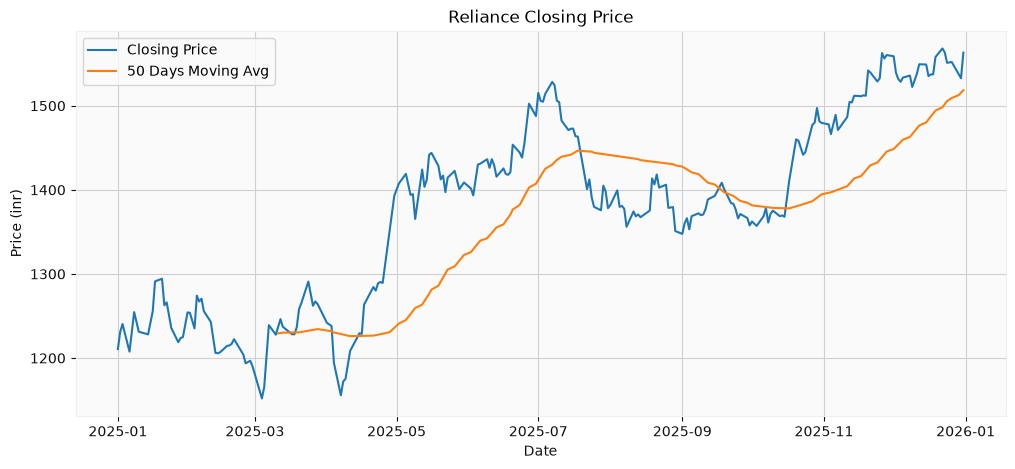

In [35]:
# Trade Chart

plt.figure(figsize=(12,5))
plt.plot(df["Close"],label="Closing Price")
plt.plot(df["MA50"],label="50 Days Moving Avg")
plt.title("Reliance Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (inr)")
plt.grid(True)
plt.legend()
plt.show()


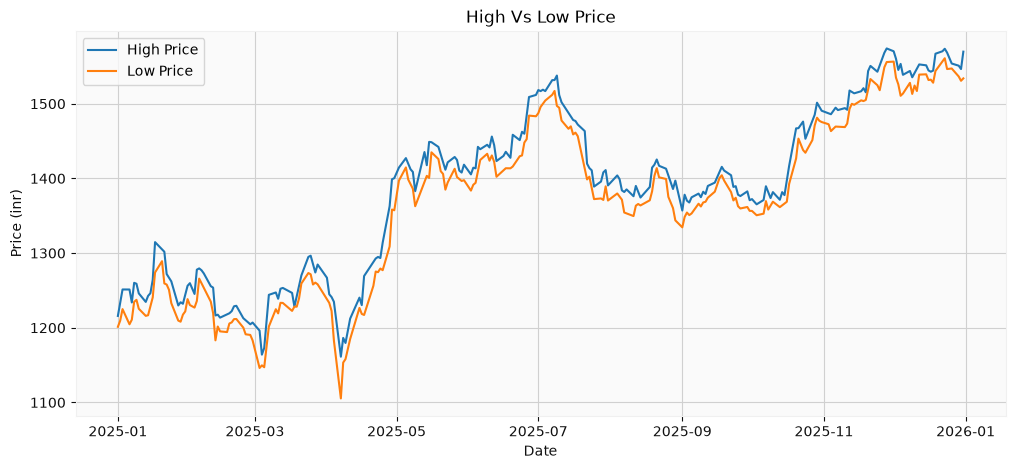

In [36]:
# High Vs Low Price

plt.figure(figsize=(12,5))
plt.plot(df["High"],label="High Price")
plt.plot(df["Low"],label="Low Price")
plt.title("High Vs Low Price")
plt.xlabel("Date")
plt.ylabel("Price (inr)")
plt.grid(True)
plt.legend()
plt.show()

In [37]:
# Trade Analysis 100 Days

df["MA100"] =df["Close"].rolling(window=100).mean()

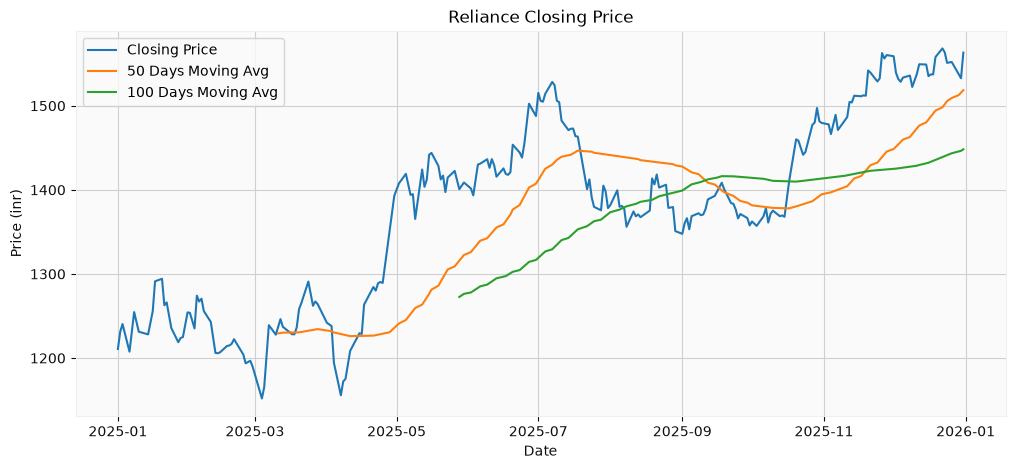

In [38]:
plt.figure(figsize=(12,5))
plt.plot(df["Close"],label="Closing Price")
plt.plot(df["MA50"],label="50 Days Moving Avg")
plt.plot(df["MA100"],label="100 Days Moving Avg")
plt.title("Reliance Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (inr)")
plt.grid(True)
plt.legend()
plt.show()

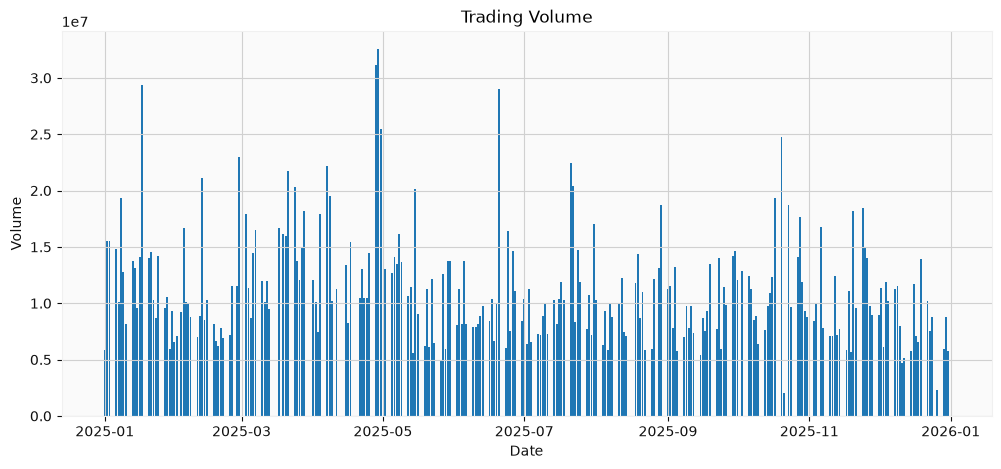

In [39]:
# Bar Chart Volume

plt.figure(figsize=(12,5))

plt.bar(df.index, df[("Volume", "RELIANCE.NS")])

plt.title("Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.show()

In [40]:
%pip install mplfinance

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
df.columns= df.columns.droplevel(1)


In [42]:
df = df.astype({
    "Open": float,
    "High": float,
    "Low": float,
    "Close": float,
    "Volume": int
})

In [43]:
df.dtypes

Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
MA50      float64
MA100     float64
dtype: object

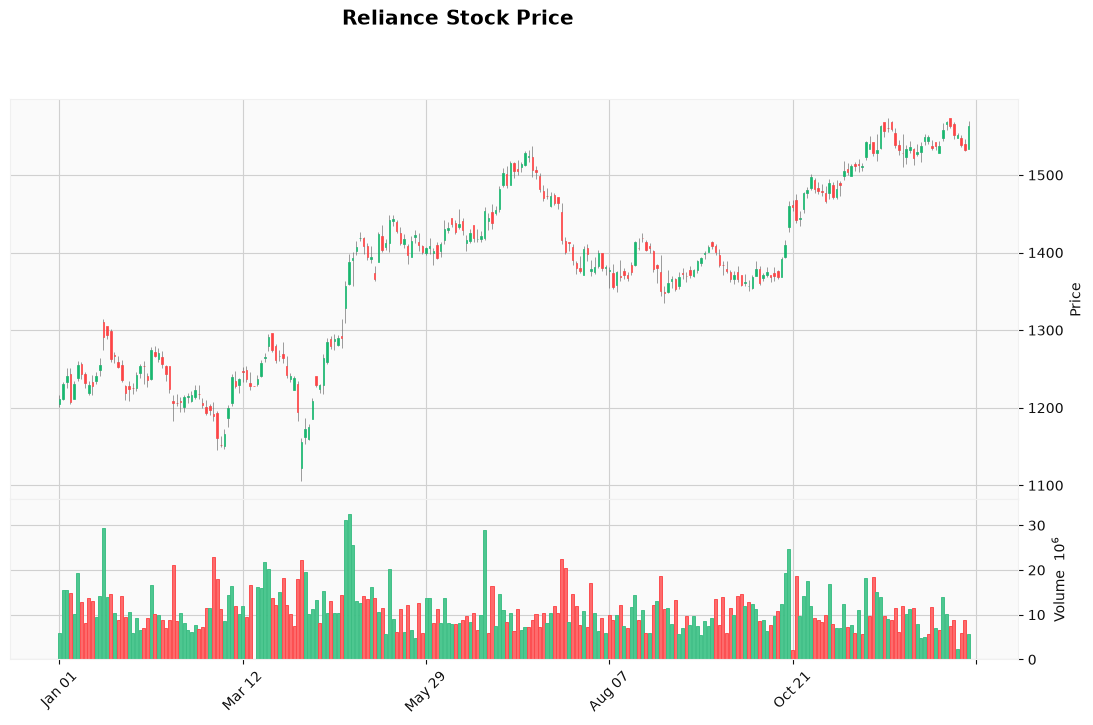

In [44]:
import mplfinance as mpf

mpf.plot(
    df,
    type="candle",
    volume=True,
    style="yahoo",
    figsize=(14,8),
    title="Reliance Stock Price"
)

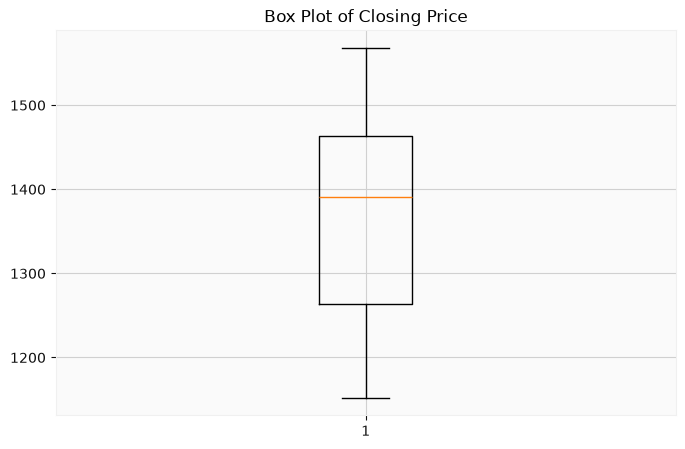

In [45]:
# Box Plot

plt.figure(figsize=(8,5))

plt.boxplot(df["Close"])

plt.title("Box Plot of Closing Price")

plt.show()

[*********************100%***********************]  2 of 2 completed


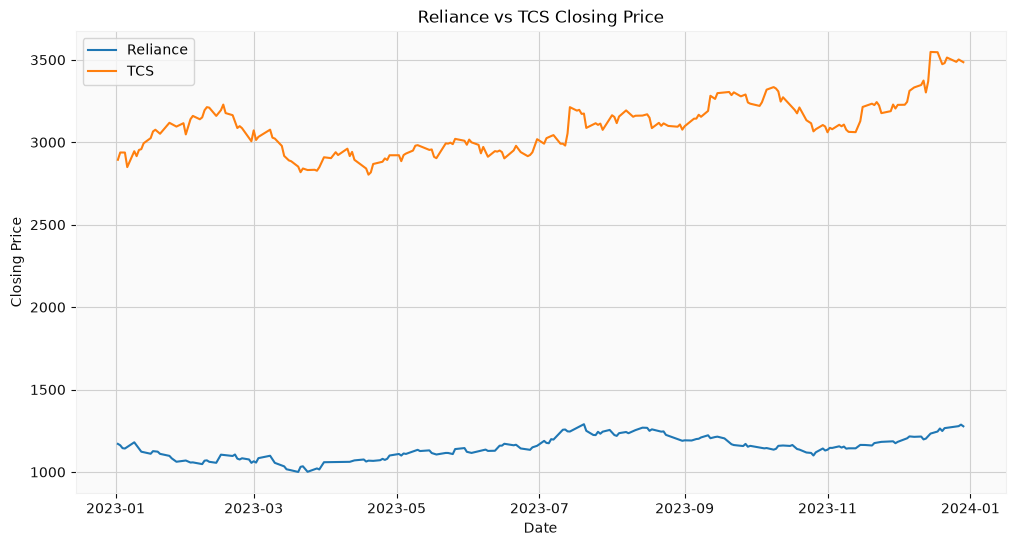

In [46]:
df = yf.download(
    ["RELIANCE.NS", "TCS.NS"],
    start="2023-01-01",
    end="2024-01-01"
)

plt.figure(figsize=(12,6))

plt.plot(df["Close"]["RELIANCE.NS"], label="Reliance")
plt.plot(df["Close"]["TCS.NS"], label="TCS")

plt.title("Reliance vs TCS Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)

plt.show()

In [47]:
df.columns

MultiIndex([( 'Close', 'RELIANCE.NS'),
            ( 'Close',      'TCS.NS'),
            (  'High', 'RELIANCE.NS'),
            (  'High',      'TCS.NS'),
            (   'Low', 'RELIANCE.NS'),
            (   'Low',      'TCS.NS'),
            (  'Open', 'RELIANCE.NS'),
            (  'Open',      'TCS.NS'),
            ('Volume', 'RELIANCE.NS'),
            ('Volume',      'TCS.NS')],
           names=['Price', 'Ticker'])

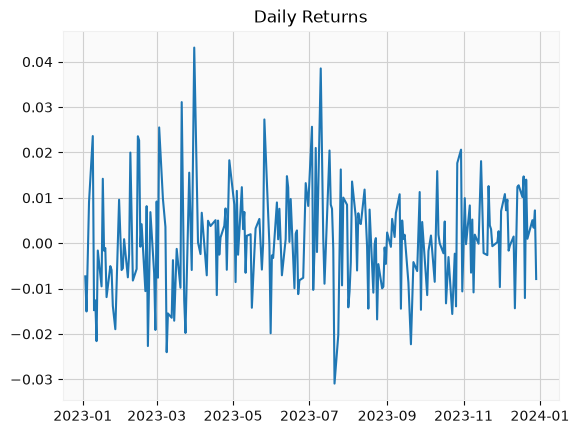

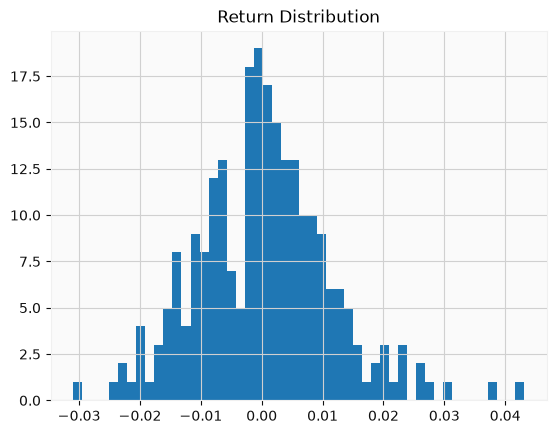

In [51]:
# Daily Return

df["Daily Return"] = df[("Close", "RELIANCE.NS")].pct_change()

plt.plot(df["Daily Return"])
plt.title("Daily Returns")
plt.show()


# Histogram Risk Analysis

plt.hist(df["Daily Return"].dropna(),bins=50)
plt.title("Return Distribution")
plt.show()